In [6]:
#from bai_utils import *
from tbp_utils import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from collections import defaultdict
from sklearn.preprocessing import normalize
import ipdb

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    theta = (2*np.random.rand(p)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

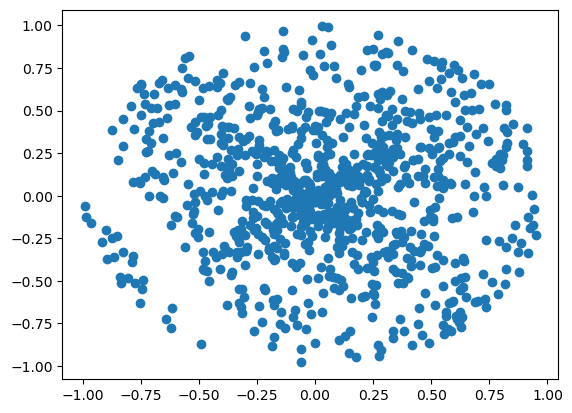

In [3]:
x, y, theta = gen_data(1000, p=2, scale=20)
rho = np.quantile(x @ theta, .95)
#np.sort(np.abs(x @ theta - rho))[:5]# < 0.01
plt.scatter(x[np.abs(x @ theta - rho) > 2, 0], x[np.abs(x @ theta - rho) > 2, 1])

In [10]:
#%pdb off

Automatic pdb calling has been turned OFF


In [63]:
mean_list = defaultdict(list)
rho_list = defaultdict(list)
epsilon_list = defaultdict(list)
gap_list = defaultdict(list)
x_list = defaultdict(list)

mean_hat_list1 = defaultdict(list)
tau_list1 = defaultdict(list)
succ_list1 = defaultdict(list)
g_arms_list1 = defaultdict(list)
perf_list1 = defaultdict(list)
A_list1 = defaultdict(list)

mean_hat_list2 = defaultdict(list)
tau_list2 = defaultdict(list)
succ_list2 = defaultdict(list)
g_arms_list2 = defaultdict(list)
perf_list2 = defaultdict(list)
A_list2 = defaultdict(list)

for eta in (1 / np.linspace(.1,10,10)):
    for i in trange(10):
        x, y, theta = gen_data(100, p=2, scale=20)

        rho = np.quantile(x @ theta, .65)
        rho_list[eta].append(rho)

        x = x[np.abs(x @ theta - rho) > eta, :]

        x_list[eta].append(x)
        epsilon = 0#(np.round(np.sort(x @ theta), 1)).std() / 100
        epsilon_list[eta].append(epsilon)
        gap_list[eta].append(np.sort(x @ theta)[-1] - np.sort(x @ theta)[-2])
        mean_list[eta].append(x @ theta)
        m, d = x.shape
        prob_dict = {
                "m": m,
                "d": d,
                "x": x,
                "theta": theta,
              }

        prob = linear_discover(**prob_dict)
        t_prob = deepcopy(prob)
        solver = G_allocation(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, 0.05)
        tau_list1[eta].append(tau)
        g_arms_list1[eta].append(g_arms)
        perf_list1[eta].append(perf)
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list1[eta].append(x @ solver.theta_hat)
        A_list1[eta].append(solver.A)

        t_prob = deepcopy(prob)
        solver = lazy_TS(t_prob, rho, epsilon)
        g_arms, perf, tau = solver.run(1000, 0.05)
        tau_list2[eta].append(tau)
        g_arms_list2[eta].append(g_arms)
        perf_list2[eta].append(perf)
    #    succ_list1.append(best == prob.best_arm)
        mean_hat_list2[eta].append(x @ solver.theta_hat)
        A_list2[eta].append(solver.A)

100%|███████████████████████████████████████████| 10/10 [00:09<00:00,  1.04it/s]


In [64]:
epsilon_list

defaultdict(list,
            {10.0: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.8333333333333333: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.4347826086956521: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.2941176470588235: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.2222222222222222: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.17857142857142858: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.14925373134328357: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.1282051282051282: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.11235955056179775: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
             0.1: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]})

In [65]:
pd.DataFrame(perf_list1)

,10.000000,0.833333,0.434783,0.294118,0.222222,0.178571,0.149254,0.128205,0.112360,0.100000
0,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
1,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
2,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
3,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
4,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
5,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
6,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
7,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
8,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
9,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"


In [66]:
pd.DataFrame(perf_list2)

,10.000000,0.833333,0.434783,0.294118,0.222222,0.178571,0.149254,0.128205,0.112360,0.100000
0,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
1,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
2,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
3,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
4,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
5,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
6,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
7,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
8,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"
9,"(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)","(0, 0)"


In [67]:
np.nanmean(pd.DataFrame(tau_list1),0)

array([  3. ,  17.6,  35.4,  76. , 102.7,  86.9, 108.5, 144.9,  98.4,
       105.9])

In [68]:
np.nanmean(pd.DataFrame(tau_list2),0)

array([  3.8,  15.8,  27.2,  52.4,  50.1,  71.8,  75.6, 146.5,  93.5,
       107.8])

In [69]:
tau_list2

defaultdict(list,
            {10.0: [5, 3, 3, 3, 3, 5, 3, 3, 5, 5],
             0.8333333333333333: [15, 11, 19, 16, 16, 25, 14, 12, 21, 9],
             0.4347826086956521: [16, 30, 26, 17, 44, 29, 30, 20, 18, 42],
             0.2941176470588235: [93, 32, 18, 73, 33, 15, 33, 137, 61, 29],
             0.2222222222222222: [71, 13, 81, 24, 18, 44, 41, 36, 118, 55],
             0.17857142857142858: [47, 80, 67, 145, 100, 77, 25, 31, 31, 115],
             0.14925373134328357: [102, 50, 47, 241, 37, 70, 36, 19, 103, 51],
             0.1282051282051282: [149, 141, 81, 38, 33, 816, 105, 46, 16, 40],
             0.11235955056179775: [154, 17, 246, 56, 119, 40, 46, 146, 18, 93],
             0.1: [86, 66, 395, 206, 36, 63, 18, 96, 32, 80]})

In [19]:
[min([np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)]) for eta in (1 / np.linspace(.1,10,10))]


[10.02144989508679,
 0.8425356970083648,
 0.4350781550058904,
 0.2985957758576261,
 0.22310136713750184,
 0.17899028885160356,
 0.15128089822135016,
 0.13303910387193868,
 0.11941688135378406,
 0.10416964005864958]

In [20]:
taus_ = np.array([[1/np.mean([np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)]), np.mean(tau_list1[eta])]  for eta in (1 / np.linspace(.1,10,10))])
taus_+1


array([[ 1.09846229,  3.8       ],
       [ 2.10203632, 15.6       ],
       [ 3.19762571, 40.5       ],
       [ 3.8414024 , 35.6       ],
       [ 4.44155683, 87.1       ],
       [ 4.51155171, 53.5       ],
       [ 5.97764292, 85.3       ],
       [ 6.61166234, 94.4       ],
       [ 6.66406263, 66.9       ],
       [ 6.44537931, 74.5       ]])

In [21]:
[np.mean([1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)])  for eta in (1 / np.linspace(.1,10,10))]


[0.0984756905861804,
 1.1079373682165148,
 2.201026763680351,
 2.864876755601875,
 3.623172513591804,
 3.817014453840386,
 5.183764494788012,
 5.949739234572678,
 6.136275587588981,
 6.017323473985487]

In [22]:
[np.nanmean(np.array([1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))]


[0.0984756905861804,
 1.1079373682165148,
 2.201026763680351,
 2.864876755601875,
 3.623172513591804,
 3.817014453840386,
 5.183764494788012,
 5.949739234572678,
 6.136275587588981,
 6.017323473985487]

In [23]:
#taus = np.array([np.nanmean(np.array([(1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus1 = np.array([np.nanmean(np.array([(np.sum(1/np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus2 = np.array([np.nanmean(np.array([(np.sum(1/np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list2[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])


In [70]:
#taus = np.array([np.nanmean(np.array([(1/np.min(np.abs(mean_list[eta][i] - rho_list[eta][i])), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus1 = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_list1[eta][i]/ tau_list1[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list1[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])
taus2 = np.array([np.nanmean(np.array([(np.max( (x_list[eta][i][:,None] @ np.linalg.inv(A_list2[eta][i] / tau_list2[eta][i]) @ x_list[eta][i][:,:,None]).flatten() /np.abs(mean_list[eta][i] - rho_list[eta][i])**2), tau_list2[eta][i]) for i in range(10)]),0 ) for eta in (1 / np.linspace(.1,10,10))])


In [45]:
(taus_[8,1] - taus_[0,1]) / (taus_[8,0] - taus_[0,0])

11.337501107578838

In [74]:
(taus1[8,1] - taus1[0,1]) / (taus1[8,0] - taus1[0,0])

5.156759685025993

In [75]:
(taus2[8,1] - taus2[0,1]) / (taus2[8,0] - taus2[0,0])

3.0297778518364806

In [61]:
taus2[:,1] / taus1[:,1]

array([1.24137931, 0.89714286, 0.87797619, 0.63358779, 0.69849246,
       0.70454545, 0.91247265, 1.01545595, 0.85512367, 0.59672467])

array([ 3.6, 15.7, 29.5, 33.2, 27.8, 68.2, 41.7, 65.7, 72.6, 58.3])

In [48]:
np.log(1/0.05)

2.995732273553991

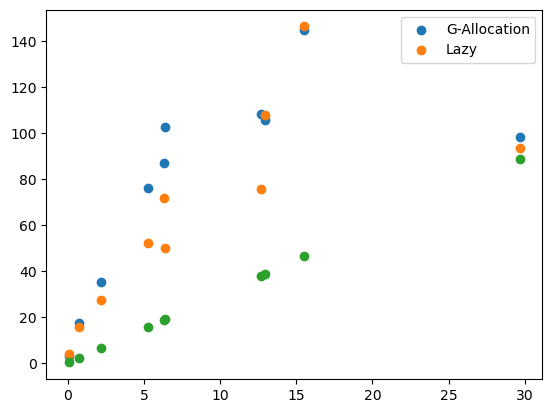

In [77]:
plt.scatter(taus2[:,0], taus1[:,1], label='G-Allocation')
plt.scatter(taus2[:,0], taus2[:,1], label='Lazy')
plt.scatter(taus2[:,0], taus2[:,0] * np.log(1/0.05))
plt.legend()
#plt.scatter(taus_[:,0], taus_[:,1])
#plt.plot(np.linspace(0,5), 30*np.linspace(0,5))

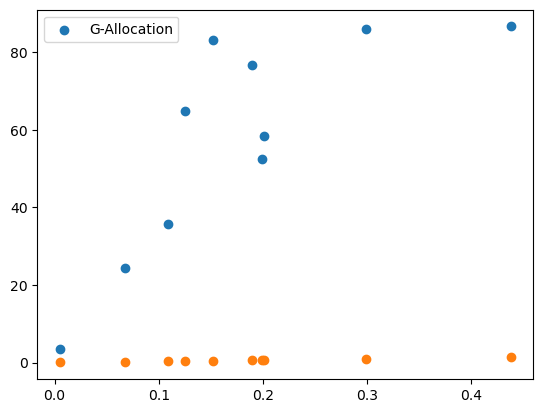

In [68]:
plt.scatter(taus1[:,0], taus1[:,1], label='G-Allocation')
#plt.scatter(taus2[:,0], taus2[:,1], label='Greedy')
plt.scatter(taus1[:,0], taus1[:,0] * np.log(1/0.05))
plt.legend()
#plt.scatter(taus_[:,0], taus_[:,1])
#plt.plot(np.linspace(0,5), 30*np.linspace(0,5))

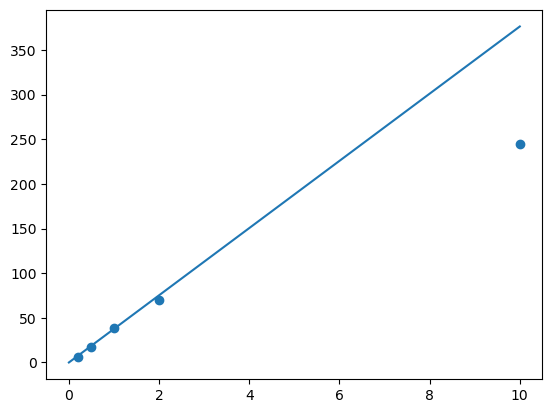

In [129]:
plt.scatter([.2,.5,1,2,10],[6.6,17.7,38.9,70.5,245.3])
plt.plot(np.linspace(0,10), 37.64*np.linspace(0,10))

In [24]:
(17.7 - 6.6) / (.5 - .2)

37.0

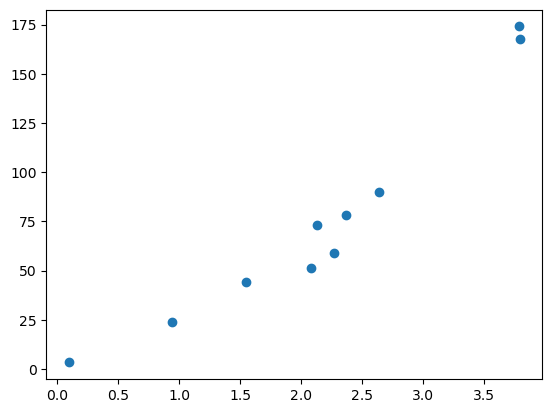

In [128]:
plt.scatter(taus[:,0], taus[:,1])

In [114]:
set(np.arange(8))> set(np.where(np.arange(10) > 5)[0])

False

In [107]:
np.setdiff1d(np.where(np.arange(10) > 5)[0], np.arange(10))

array([], dtype=int64)

In [43]:
mean_list[0][~good_arms].shape

(948,)

In [44]:
mean_list[0][good_arms].shape

(52,)

In [127]:
for eta in (1 / np.linspace(.1,10,10)):
    for i in range(10):
        good_arms = mean_hat_list1[eta][i] > rho_list[eta][i]
        #print((mean_list[10.0][i][good_arms] + epsilon_list[10.0][i] <= rho_list[10.0][i]).sum(), (mean_list[10.0][i][~good_arms] - epsilon_list[10.0][i] > rho_list[10.0][i]).sum())
        print((mean_list[eta][i][good_arms] + 0 <= rho_list[eta][i]).sum(), (mean_list[eta][i][~good_arms] - 0 > rho_list[eta][i]).sum())


0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0
0 0


In [78]:
epsilon = 0
rest_list1 = []
rest_list2 = []
for j in range(10):
    list_1 = []
    list_2 = []
    #j = 4
    mean_norm = (mean_list[j] - min(mean_list[j])) / (max(mean_list[j]) - min(mean_list[j]))
    mean_hat_norm = (mean_hat_list1[j] - min(mean_hat_list1[j])) / (max(mean_hat_list1[j]) - min(mean_hat_list1[j]))

    for rho in np.linspace(0, 1, 100):
        good_arms = mean_hat_norm > rho
        list_1.append((mean_norm[good_arms] + epsilon <= rho).sum())
        list_2.append((mean_norm[~good_arms] - epsilon > rho).sum())
    
    rest_list1.append(list_1)
    rest_list2.append(list_2)
    #plt.scatter(np.linspace(0,1, 100), list_1)    
    
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list1) > 1).mean(0), label='false good')
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list2) > 1).mean(0), label='false bad')
plt.legend()

ValueError: min() arg is an empty sequence

In [4]:
x, y, theta = gen_data(1000, p=2, scale=20)
rho = np.quantile(x @ theta, .5)
x = x[np.abs(x @ theta - rho) > 5, :]  
epsilon = (np.round(np.sort(x @ theta), 1)).std() / 100
m, d = x.shape
prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
          }

prob = linear_discover(**prob_dict)
t_prob = deepcopy(prob)
solver = G_allocation(t_prob, rho)
reg, rwd, best, tau = solver.run(1000, 0.05, epsilon=epsilon, sampling_rule=1)   

In [13]:
epsilon

0.11207914691634865

In [6]:
tau

nan

In [7]:
len(solver.prob.actions)

1000

In [22]:
delta = 0.05
t = 1000
x = solver.prob.x
A_inv = solver.sigma_hat
C = np.log(solver.prob.m ** 2 / delta) / np.log(t)
theta_hat = solver.theta_hat
m = solver.prob.m
        
        #gaps = ((x - x[:,None]).reshape(-1, 2) @ theta_hat).reshape(m,m)
gap = np.abs(x @ theta_hat - solver.rho).min()
        
norms = (np.sqrt(x[:,None] @ A_inv @ x[:,:,None]).flatten())
        
(norms * C < np.abs(x @ theta_hat - solver.rho) + epsilon).sum()# == m - 1

527

In [21]:
m

527

In [11]:
C

2.2482170753630246

In [12]:
rho

0.0411185039419723

In [14]:
np.abs(x @ theta_hat - solver.rho)[np.where(~(norms * C < np.abs(x @ theta_hat - solver.rho)))[0]] + 0.05

array([], dtype=float64)

In [15]:
(np.round(np.sort(x @ theta), 1)).std()

11.207914691634866

In [16]:
(norms * C)[np.where(~(norms * C < np.abs(x @ theta_hat - solver.rho)))[0]]

array([], dtype=float64)

In [33]:
gaps = np.arange(11)-5

array([ 6,  7,  8,  9, 10])

In [40]:
gaps = np.delete(gaps, np.where(gaps <= 0)[0],0 )

In [41]:
gaps

array([1, 2, 3, 4, 5])